# PBL JS06 - Approximate Nearest Neighbors untuk Pencarian URL Mirip

**Nama:** Agus
**NIM:** 244107020049

[Sumber modul](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js06-ann-approximate-nearest-neighbors)

Notebook ini menerapkan langkah-langkah jobsheet JS06 pada **dataset PBL: Malicious URL Detection**
(`Malicious URL Detection.csv` di root repositori). Dataset berisi 783.705 URL dengan kolom `url` dan `type`, terbagi ke 7 kelas:
`benign`, `legitimate`, `defacement`, `phishing`, `malware`, `spam`, dan `Exploit`.
URL sudah dinormalisasi oleh sumbernya (huruf kecil, tanpa `http(s)://` dan `www.`).
Fungsi muat data dan ekstraksi fitur leksikal ada di modul bersama [`pbl_url.py`](../pbl_url.py), sehingga semua notebook PBL memakai definisi fitur yang sama.

**Pemetaan langkah jobsheet → dataset PBL:**


| Jobsheet JS06 | Penerapan pada URL |
| --- | --- |
| Praktikum 1-3 - Exact NN, Annoy, FAISS (Flat, IVF+PQ), HNSW | Indeks 300.000 URL dalam ruang embedding 64 dimensi |
| Praktikum 4-5 - Perbandingan waktu build, waktu query, QPS, recall | Recall@10 terhadap exact NN dan QPS untuk 2.000 query |
| Praktikum 6 - Pencarian item mirip (Spotify) | "URL paling mirip" dan klasifikasi kNN dari tetangga ANN |

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pbl_url
np.random.seed(42)
print('Kernel:', sys.executable)

Kernel: /Users/jergal/College/machine-learning-smt-5/.venv/bin/python


## Langkah 1 - Representasi URL sebagai vektor

Pada praktikum Spotify, setiap lagu adalah vektor fitur numerik. Di sini setiap URL diubah menjadi vektor dengan **TF-IDF n-gram karakter 3-5**,
lalu direduksi dengan **TruncatedSVD (LSA)** menjadi 64 dimensi dan dinormalisasi L2. Setelah normalisasi L2, jarak Euclidean
dan kemiripan kosinus menghasilkan urutan tetangga yang sama.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize
df = pbl_url.load_urls()
base, query = train_test_split(df, train_size=300000, test_size=2000, stratify=df['type'], random_state=42)
t0 = time.perf_counter()
tfidf = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=3, max_features=200000, sublinear_tf=True, dtype=np.float32)
svd = TruncatedSVD(64, random_state=42)
xb = normalize(svd.fit_transform(tfidf.fit_transform(base['url']))).astype('float32')
xq = normalize(svd.transform(tfidf.transform(query['url']))).astype('float32')
print(f'Embedding: base {xb.shape}, query {xq.shape}, {time.perf_counter() - t0:.1f} s; varians SVD {svd.explained_variance_ratio_.sum():.3f}')
yb, yq = base['type'].to_numpy(), query['type'].to_numpy()
K = 10

Embedding: base (300000, 64), query (2000, 64), 36.4 s; varians SVD 0.104


## Langkah 2 - Exact NN (brute force, FAISS IndexFlatIP) sebagai ground truth

In [3]:
import faiss
t0 = time.perf_counter(); flat = faiss.IndexFlatIP(64); flat.add(xb); t_build = time.perf_counter() - t0
t0 = time.perf_counter(); D_ex, I_ex = flat.search(xq, K); t_q = time.perf_counter() - t0
results = [{'metode': 'Exact (FAISS Flat)', 'build_s': t_build, 'query_s': t_q, 'QPS': len(xq) / t_q, 'recall@10': 1.0, 'I': I_ex}]
print(f'Exact: query {len(xq)} URL dalam {t_q:.3f} s')

Exact: query 2000 URL dalam 0.134 s


## Langkah 3 - Annoy

In [4]:
from annoy import AnnoyIndex
def recall(I):
    return np.mean([len(set(a) & set(b)) / K for a, b in zip(I, I_ex)])
for trees in [10, 50]:
    t0 = time.perf_counter(); ann = AnnoyIndex(64, 'angular')
    for i, v in enumerate(xb): ann.add_item(i, v)
    ann.build(trees, n_jobs=-1); t_build = time.perf_counter() - t0
    t0 = time.perf_counter(); I = np.array([ann.get_nns_by_vector(v, K) for v in xq]); t_q = time.perf_counter() - t0
    results.append({'metode': f'Annoy ({trees} tree)', 'build_s': t_build, 'query_s': t_q, 'QPS': len(xq) / t_q, 'recall@10': recall(I), 'I': I})

## Langkah 4 - FAISS IVF dan IVF+PQ

In [5]:
for name, factory, nprobe in [('FAISS IVF1024,Flat', 'IVF1024,Flat', 16), ('FAISS IVF1024,PQ16', 'IVF1024,PQ16', 16)]:
    t0 = time.perf_counter(); idx = faiss.index_factory(64, factory, faiss.METRIC_INNER_PRODUCT); idx.train(xb); idx.add(xb); t_build = time.perf_counter() - t0
    idx.nprobe = nprobe
    t0 = time.perf_counter(); _, I = idx.search(xq, K); t_q = time.perf_counter() - t0
    results.append({'metode': f'{name} (nprobe={nprobe})', 'build_s': t_build, 'query_s': t_q, 'QPS': len(xq) / t_q, 'recall@10': recall(I), 'I': I})

## Langkah 5 - HNSW (hnswlib)

In [6]:
import hnswlib
t0 = time.perf_counter(); hn = hnswlib.Index(space='cosine', dim=64); hn.init_index(max_elements=len(xb), ef_construction=200, M=16)
hn.add_items(xb, num_threads=-1); t_build = time.perf_counter() - t0
for ef in [20, 100]:
    hn.set_ef(ef)
    t0 = time.perf_counter(); I, _ = hn.knn_query(xq, k=K, num_threads=1); t_q = time.perf_counter() - t0
    results.append({'metode': f'HNSW (M=16, ef={ef})', 'build_s': t_build, 'query_s': t_q, 'QPS': len(xq) / t_q, 'recall@10': recall(I), 'I': I})

## Langkah 6 - Perbandingan recall, waktu, dan klasifikasi kNN dari tetangga

,build_s,query_s,QPS,recall@10,kNN_accuracy,kNN_macro_F1
metode,,,,,,
Exact (FAISS Flat),0.0035,0.1338,14942.9320,1.0000,0.8540,0.6905
Annoy (10 tree),5.8123,0.0434,46045.1096,0.4874,0.8230,0.6692
Annoy (50 tree),26.3759,0.2099,9530.0816,0.7810,0.8475,0.6625
"FAISS IVF1024,Flat (nprobe=16)",2.0282,0.0296,67606.0162,0.9849,0.8535,0.6863
"FAISS IVF1024,PQ16 (nprobe=16)",9.3997,0.0147,136400.4521,0.4486,0.8445,0.6602
"HNSW (M=16, ef=20)",5.2877,0.0343,58274.7051,0.9648,0.8525,0.6887
"HNSW (M=16, ef=100)",5.2877,0.1022,19560.6754,0.9880,0.8540,0.6904


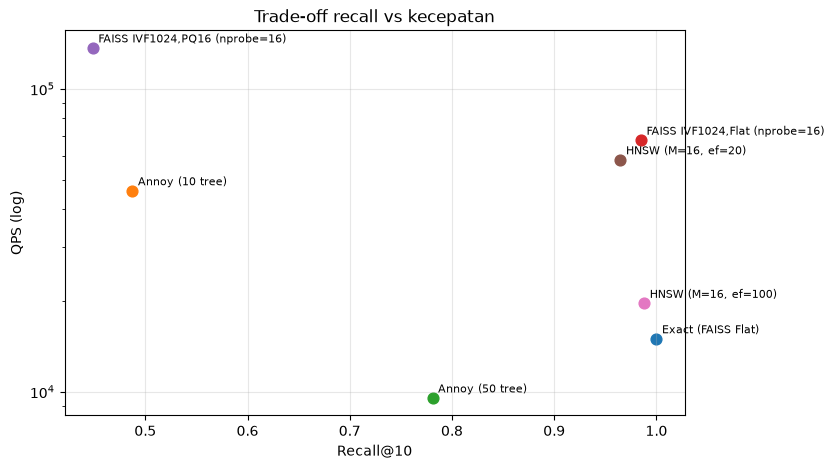

In [7]:
from sklearn.metrics import accuracy_score, f1_score
def knn_vote(I):
    return np.array([pd.Series(yb[row]).value_counts().index[0] for row in I])
for r in results:
    pred = knn_vote(r['I'])
    r['kNN_accuracy'] = accuracy_score(yq, pred); r['kNN_macro_F1'] = f1_score(yq, pred, average='macro')
res = pd.DataFrame(results).drop(columns='I').set_index('metode')
display(res.round(4))
fig, ax = plt.subplots(figsize=(8, 5))
for m, r in res.iterrows():
    ax.scatter(r['recall@10'], r['QPS'], s=60); ax.annotate(m, (r['recall@10'], r['QPS']), fontsize=8, xytext=(4, 4), textcoords='offset points')
ax.set_yscale('log'); ax.set_xlabel('Recall@10'); ax.set_ylabel('QPS (log)'); ax.set_title('Trade-off recall vs kecepatan'); ax.grid(alpha=.3); plt.show()

## Langkah 7 - Contoh pencarian URL mirip (seperti pencarian lagu mirip di Praktikum 6)

In [8]:
hn.set_ef(100)
for qi in [int(np.where(yq == t)[0][0]) for t in ['phishing', 'malware', 'defacement']]:
    I, Dd = hn.knn_query(xq[qi:qi + 1], k=5)
    print(f"QUERY [{yq[qi]}] {query['url'].iloc[qi][:90]}")
    for j, dist in zip(I[0], Dd[0]):
        print(f'   {1 - dist:.3f}  [{yb[j]}] {base["url"].iloc[j][:90]}')

QUERY [phishing] urheagq.com
   0.998  [phishing] urheazq.com
   0.997  [phishing] urxeatq.com
   0.995  [phishing] urhebjq.com
   0.995  [benign] avt-hq.com
   0.994  [phishing] chchqq.com
QUERY [malware] rimmugygur.is/jaextmanager_data/rimm.bin
   0.837  [phishing] madersilva.com.br/language/overrides/fr/www.banque-populaire.fr/portailinternet/e145bddb4a
   0.810  [phishing] filemanager24.ru
   0.789  [benign] dompimenta.com.br/images/www.securityaol.com/update.php
   0.787  [phishing] conexaoengenharia.com.br/images/update/mailer%20daemon/pop/pop.htm?wendy@visent.com
   0.785  [phishing] caravellaltda.com.br/profiles/standard/update/cs/customer_center/xbanana-motherfucker894/m
QUERY [defacement] openup.nl/activiteiten/open-up-tour/jongerencampings
   0.999  [defacement] openup.nl/activiteiten/open-up-tour/jongerencampings?vsig24_0=4
   0.999  [defacement] openup.nl/activiteiten/open-up-tour/jongerencampings?vsig24_0=2
   0.999  [defacement] openup.nl/activiteiten/open-up-tour/jonger

## Analisis

| Metode | Build (s) | QPS | Recall@10 | kNN acc | kNN macro-F1 |
| --- | --- | --- | --- | --- | --- |
| Exact (FAISS Flat) | 0,00 | 14.943 | 1,000 | 0,854 | 0,691 |
| Annoy 10 tree | 5,8 | 46.045 | 0,487 | 0,823 | 0,669 |
| Annoy 50 tree | 26,4 | 9.530 | 0,781 | 0,848 | 0,663 |
| FAISS IVF1024,Flat (nprobe 16) | 2,0 | 67.606 | 0,985 | 0,854 | 0,686 |
| FAISS IVF1024,PQ16 | 9,4 | 136.400 | 0,449 | 0,845 | 0,660 |
| HNSW M=16, ef=20 | 5,3 | 58.275 | 0,965 | 0,853 | 0,689 |
| **HNSW M=16, ef=100** | 5,3 | 19.561 | **0,988** | **0,854** | **0,690** |

* **Trade-off recall vs kecepatan** terlihat jelas, sesuai ANN-Benchmarks (Aumüller dkk., 2020). HNSW dan FAISS IVF-Flat mencapai recall ≥ 0,96 dengan build cepat, dan HNSW ef=100 hampir sama dengan exact (0,988). Pada embedding 64 dimensi ini, Annoy membutuhkan 50 tree (build 26 detik) untuk recall 0,78, sesuai pengamatan bahwa pohon proyeksi acak melemah pada dimensi yang lebih tinggi. IVF+PQ paling cepat (136 ribu QPS) dengan memori terkecil, tetapi kompresi 16 byte per vektor menurunkan recall ke 0,45 (Jégou dkk., 2011).
* **Catatan keadilan pengukuran.** Exact dan FAISS memproses 2.000 query sekaligus dengan BLAS multithread, sedangkan Annoy dan HNSW di sini memproses query satu per satu atau dalam satu thread. Karena itu, pencarian exact 300 ribu vektor masih sangat cepat (0,13 detik). Untuk koleksi berukuran jutaan atau query real-time satu per satu, keunggulan ANN akan lebih terasa (Malkov & Yashunin, 2020).
* **Recall rendah tidak selalu berarti klasifikasi buruk.** Akurasi kNN (k = 10, voting mayoritas) hanya turun dari 0,854 (exact) ke 0,823-0,848 pada indeks dengan recall 0,45-0,78. Tetangga "aproksimasi" biasanya tetap berasal dari kelas yang sama. Akurasi kNN 0,854 dan macro-F1 0,69 berada di bawah model linier TF-IDF (PBL JS03, macro-F1 0,84), karena reduksi SVD 64 dimensi hanya mempertahankan 10,4% varians TF-IDF.
* **Contoh pencarian.** Query phishing `urheagq.com` menemukan domain acak yang hampir identik (`urheazq.com`, `urxeatq.com`) dengan kemiripan > 0,99. Ini pola domain hasil *domain generation algorithm*, sehingga pencarian kemiripan berguna untuk memperluas daftar blokir dari satu URL yang sudah diketahui jahat. Query malware `.bin` tidak memiliki tetangga malware yang dekat (kemiripan maksimum 0,84), sehingga kelas yang jarang dan beragam sulit ditangani kNN.
* **Catatan teknis.** Annoy 1.17.3 yang di-compile dengan flag bawaan (`-ffast-math`) di macOS ini selalu mengembalikan hanya 1 tetangga, sehingga recall-nya 0. Annoy kemudian di-compile ulang dengan `ANNOY_COMPILER_ARGS="-O2,-std=c++14"` dan hasilnya kembali benar (lihat README).

## Rujukan

1. Aumüller, M., Bernhardsson, E., & Faithfull, A. (2020). ANN-Benchmarks: A benchmarking tool for approximate nearest neighbor algorithms. *Information Systems*, 87, 101374. https://doi.org/10.1016/j.is.2019.02.006
2. Malkov, Y. A., & Yashunin, D. A. (2020). Efficient and robust approximate nearest neighbor search using hierarchical navigable small world graphs. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 42(4), 824-836. https://doi.org/10.1109/TPAMI.2018.2889473
3. Johnson, J., Douze, M., & Jégou, H. (2021). Billion-scale similarity search with GPUs. *IEEE Transactions on Big Data*, 7(3), 535-547. https://doi.org/10.1109/TBDATA.2019.2921572
4. Jégou, H., Douze, M., & Schmid, C. (2011). Product quantization for nearest neighbor search. *IEEE Transactions on Pattern Analysis and Machine Intelligence*, 33(1), 117-128. https://doi.org/10.1109/TPAMI.2010.57
5. Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K., & Harshman, R. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science*, 41(6), 391-407.
6. Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27. https://doi.org/10.1109/TIT.1967.1053964
7. Ma, J., Saul, L. K., Savage, S., & Voelker, G. M. (2009). Beyond blacklists: Learning to detect malicious web sites from suspicious URLs. *Proceedings of the 15th ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*, 1245-1254. https://doi.org/10.1145/1557019.1557153